# 01 - Data understanding and preprocessing
**Project:** Bike Sharing Demand Prediction (UCI ID 275, `hour.csv`)
**Task:** regression - predict `cnt`, the number of bikes rented in one hour.
**Milestone 2.** Lead: Nouf (Data lead). Reviewed by: Ajwan.

All statistics and figures below use the **training part only**, so nothing we learn here comes from the test set.

In [1]:
# Setup: make the project root importable (works in Jupyter and in Colab
# after `%cd <repo>/notebooks`).
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.utils import *
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

def save(fig, name):
    """Save a figure to report/figures so it can go straight into the report."""
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160)
    plt.show()

## 1. Load the data and describe it

In [2]:
df = load_data()
print("Shape:", df.shape)          # brief: 17,379 rows
print("Period:", df["timestamp"].min(), "->", df["timestamp"].max())
df.head()

Shape: (17379, 18)
Period: 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,timestamp
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.288,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.273,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.273,0.80,0.0,5,27,32,2011-01-01 02:00:00
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.288,0.75,0.0,3,10,13,2011-01-01 03:00:00
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.288,0.75,0.0,0,1,1,2011-01-01 04:00:00


In [3]:
df.dtypes

instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
timestamp     datetime64[us]
dtype: object

| Column | Meaning |
|---|---|
| `season` | 1 winter, 2 spring, 3 summer, 4 fall |
| `yr` | 0 = 2011, 1 = 2012 |
| `mnth`, `hr`, `weekday` | month 1-12, hour 0-23, day 0-6 |
| `holiday`, `workingday` | 0/1 flags |
| `weathersit` | 1 clear ... 4 heavy rain/snow |
| `temp`, `atemp`, `hum`, `windspeed` | normalised weather values (0-1) |
| `casual`, `registered` | user counts, **sum to `cnt` - removed (leakage)** |
| `cnt` | **target** |

## 2. Train/test split - done first
The rows are ordered by date + hour. The earliest 80% is training data and the latest 20% is the test set, which stays untouched until notebook 03.

In [4]:
train, test = load_split()
print("Train:", train.shape, train["timestamp"].min(), "->", train["timestamp"].max())
print("Test: ", test.shape, test["timestamp"].min(), "->", test["timestamp"].max())

Train: (13903, 18) 2011-01-01 00:00:00 -> 2012-08-07 11:00:00
Test:  (3476, 18) 2012-08-07 12:00:00 -> 2012-12-31 23:00:00


## 3. Data quality checks (training data)

In [5]:
print(check_missing(train))          # helper from src/utils.py
print("Duplicate timestamps:", train["timestamp"].duplicated().sum())

# hours that should exist but are absent from the file
full_range = pd.date_range(train["timestamp"].min(), train["timestamp"].max(), freq="h")
print("Missing hours in timeline:", len(full_range) - train["timestamp"].nunique())

Rows: 13,903 | duplicate rows: 0 | total missing values: 0
Empty DataFrame
Columns: [missing, missing_%]
Index: []
Duplicate timestamps: 0
Missing hours in timeline: 125


In [6]:
# category values - look for rare or inconsistent codes
for col in CATEGORICAL:
    print(col, {int(k): int(v) for k, v in train[col].value_counts().sort_index().items()})

season {1: 3980, 2: 4409, 3: 3380, 4: 2134}
mnth {1: 1429, 2: 1341, 3: 1473, 4: 1437, 5: 1488, 6: 1440, 7: 1488, 8: 887, 9: 717, 10: 743, 11: 719, 12: 741}
hr {0: 581, 1: 580, 2: 571, 3: 556, 4: 554, 5: 573, 6: 581, 7: 583, 8: 583, 9: 583, 10: 583, 11: 583, 12: 583, 13: 583, 14: 583, 15: 583, 16: 584, 17: 584, 18: 582, 19: 582, 20: 582, 21: 582, 22: 582, 23: 582}
holiday {0: 13522, 1: 381}
weekday {0: 1998, 1: 1999, 2: 1975, 3: 1971, 4: 1969, 5: 1983, 6: 2008}
workingday {0: 4387, 1: 9516}
weathersit {1: 9251, 2: 3468, 3: 1181, 4: 3}


In [7]:
# outliers and skew in the numeric columns
num = train[["temp", "atemp", "hum", "windspeed", "cnt"]]
summary = num.describe().T
summary["skew"] = num.skew()
q1, q3 = num.quantile(.25), num.quantile(.75)
summary["IQR_outliers"] = ((num < q1 - 1.5*(q3-q1)) | (num > q3 + 1.5*(q3-q1))).sum()
summary["zeros"] = (num == 0).sum()
summary.to_csv(RESULTS / "training_summary.csv")
summary

,count,mean,std,min,25%,50%,75%,max,skew,IQR_outliers,zeros
temp,13903.0,0.499,0.198,0.02,0.340,0.500,0.660,1.000,-0.034,0,0
atemp,13903.0,0.478,0.177,0.00,0.333,0.485,0.621,1.000,-0.117,0,2
hum,13903.0,0.623,0.198,0.00,0.470,0.620,0.790,1.000,-0.096,0,22
windspeed,13903.0,0.194,0.123,0.00,0.104,0.194,0.284,0.851,0.578,91,1639
cnt,13903.0,174.639,166.955,1.00,37.000,130.000,258.000,957.000,1.281,396,0


**Findings (training data, 13,903 rows):** no missing values and no duplicate rows or timestamps. 125 hours are absent from the timeline (system or recording downtime); we keep the data as it is. `weathersit = 4` (heavy rain/snow) occurs only 3 times, so the model cannot learn it reliably. `cnt` is right-skewed (skewness 1.28) and has 396 values above the IQR fence; these are real rush hours, not errors, so we keep them. `hum = 0` appears 22 times and `windspeed = 0` 1,639 times, which suggests recording problems; we keep them and mention this as a limitation.

## 4. Exploratory figures (training data)

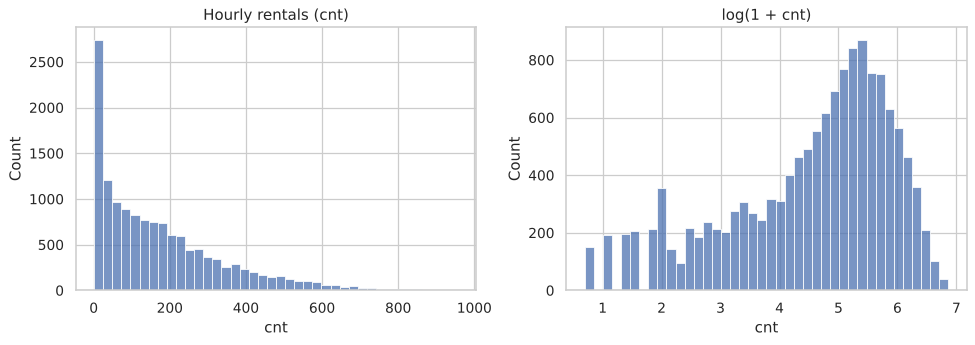

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(train["cnt"], bins=40, ax=ax[0]).set(title="Hourly rentals (cnt)")
sns.histplot(np.log1p(train["cnt"]), bins=40, ax=ax[1]).set(title="log(1 + cnt)")
save(fig, "fig1_target_distribution.png")

**Figure 1 interpretation:** hourly demand is strongly right-skewed (median 130, mean 175, maximum 957): many quiet night hours and few very busy ones. `log(1 + cnt)` is much more symmetric, which is why a log-target model is tested in notebook 02.

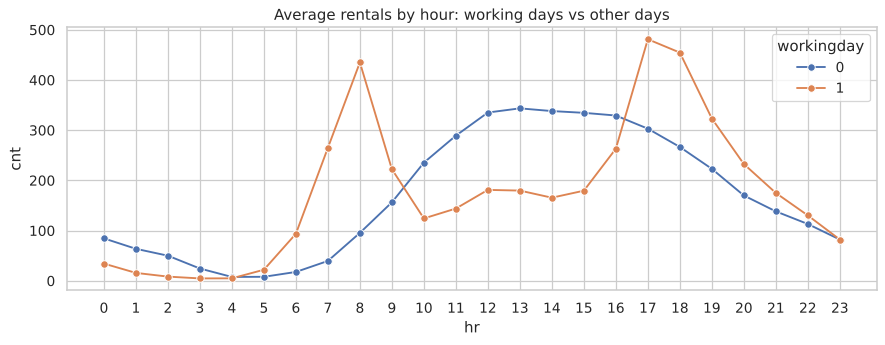

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=train, x="hr", y="cnt", hue="workingday", errorbar=None, marker="o", ax=ax)
ax.set(title="Average rentals by hour: working days vs other days", xticks=range(24))
save(fig, "fig2_hour_workingday.png")

**Figure 2 interpretation:** working days show two commuting peaks, about 435 rentals at 08:00 and 481 at 17:00, while non-working days have one broad midday peak (about 340 between 12:00 and 15:00) and almost no morning rush. Hour and working day interact strongly, which an additive linear model cannot represent but a tree can.

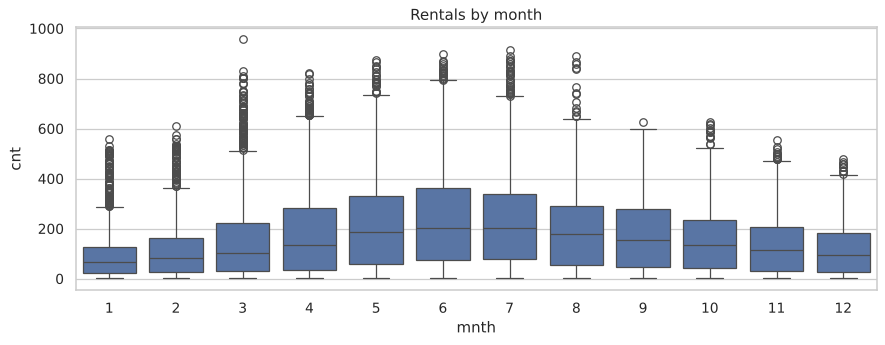

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=train, x="mnth", y="cnt", ax=ax).set(title="Rentals by month")
save(fig, "fig3_month.png")

**Figure 3 interpretation:** median demand is lowest in January (66) and highest in June-July (about 200), so season and temperature matter. Months 8-12 have fewer training rows because the later part of 2012 belongs to the test set.

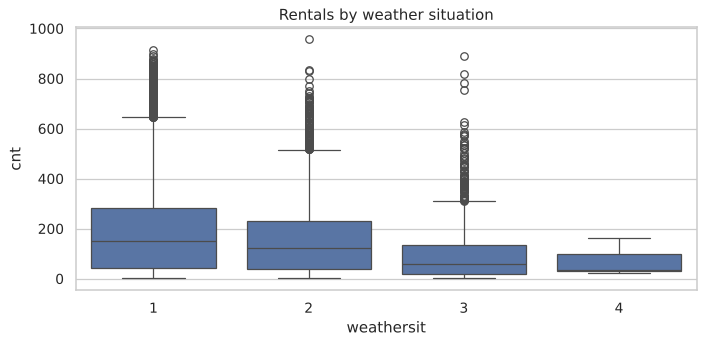

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=train, x="weathersit", y="cnt", ax=ax).set(title="Rentals by weather situation")
save(fig, "fig4_weather.png")

**Figure 4 interpretation:** demand falls as weather worsens: median 149 in clear weather, 121 with mist and 58 with light rain/snow. Category 4 has only 3 rows.

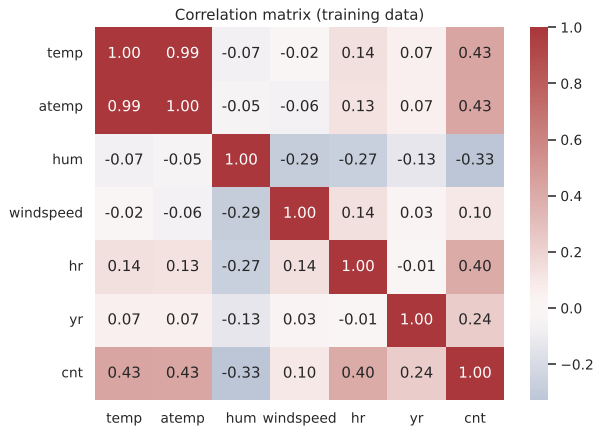

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
corr = train[["temp", "atemp", "hum", "windspeed", "hr", "yr", "cnt"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set(title="Correlation matrix (training data)")
corr.to_csv(RESULTS / "correlations.csv")
save(fig, "fig5_correlation.png")

**Figure 5 interpretation:** `temp` and `atemp` are almost identical (r = 0.99), so one is redundant; this makes linear-model coefficients unstable (a reason to try Ridge) but does not hurt trees. Demand correlates positively with temperature (0.43), hour (0.40) and year (0.24) and negatively with humidity (-0.33). Hour is not truly linear (Figure 2), so its real effect is stronger than r suggests.

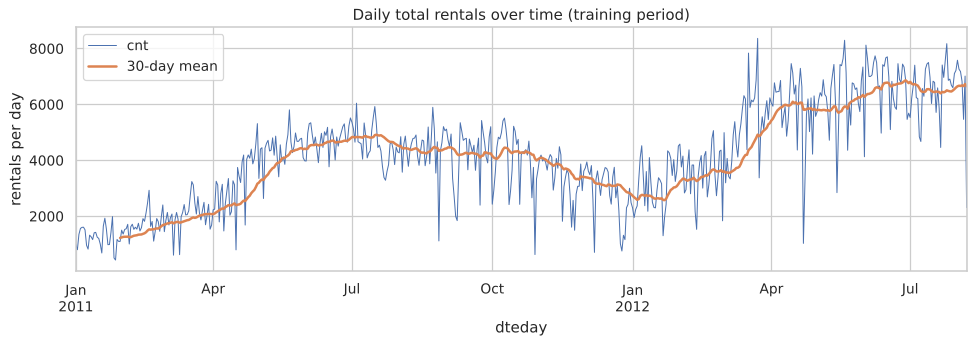

In [13]:
daily = train.groupby("dteday")["cnt"].sum()
fig, ax = plt.subplots(figsize=(11, 4))
daily.index = pd.to_datetime(daily.index)
daily.plot(ax=ax, lw=.8)
daily.rolling(30).mean().plot(ax=ax, lw=2, label="30-day mean")
ax.set(title="Daily total rentals over time (training period)", ylabel="rentals per day")
ax.legend()
save(fig, "fig6_trend.png")

**Figure 6 interpretation:** daily rentals follow a seasonal cycle and grow strongly from 2011 to 2012 (mean hourly demand 144 in 2011 vs 225 in 2012 within the training period). `yr` is kept as a feature. The risk is that the test period (Aug-Dec 2012, mean 249) is busier than most of the training data. The last point drops because 7 Aug 2012 is only partly in the training set.

## 5. Preprocessing decisions
| Decision | Reason |
|---|---|
| Drop `casual`, `registered` | They add up to `cnt` - target leakage |
| Drop `instant`, `dteday`, `timestamp` | Row id / raw date; the date information is already in `yr`, `mnth`, `weekday`, `hr` |
| Keep outliers in `cnt` | Real busy hours, not errors |
| **Linear / k-NN / NN:** one-hot encode codes, standard-scale numbers | Codes like `hr` are not linear quantities; distance and gradient methods need comparable scales |
| **Trees / ensembles:** keep integer codes, no scaling | Trees split on thresholds; the hour order is useful and scaling changes nothing |
| Imputers in the pipeline | No missing values now, but the pipeline stays safe for new data |
| Target skew | Tested with a log-target model (`TransformedTargetRegressor`) in notebook 02 |
| All steps inside `Pipeline` + `ColumnTransformer` | Fitted on training folds only -> no leakage into validation or test |

Class imbalance does not apply (regression); the equivalent issue is the skewed target, handled above.

In [14]:
X_train, y_train = xy(train)
print("Model features:", list(X_train.columns))
prep = preprocessing("linear").fit(X_train)       # fitted on TRAINING rows only
print("Linear preprocessing output shape:", prep.transform(X_train).shape)
print("Tree preprocessing output shape:  ", preprocessing("tree").fit_transform(X_train).shape)
prep

Model features: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
Linear preprocessing output shape: (13903, 60)
Tree preprocessing output shape:   (13903, 12)


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['temp', 'atemp', 'hum', 'windspeed', 'yr']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['season', 'mnth', 'hr', 'holiday', 'weekday',
                                  'workingday', 'weathersit'])])